# CITS5508 - Assignment 2 2026

Dipika Choudhury - 23779727

## Part 1 - Ensemble Learning for Heart Disease Prediction

### 1. Load the dataset and assign appropriate column names.

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

heart = pd.read_csv(
    "processed.cleveland.data",
    names=column_names,
    na_values="?"
)

heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [49]:
print("Original shape:", heart.shape)

print("\nMissing values:")
print(heart.isna().sum())

heart = heart.dropna()

print("\nShape after dropping the values that are missing:", heart.shape)

Original shape: (303, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Shape after dropping the values that are missing: (297, 14)


### Briefly describe the dataset:
### (a) How many examples are there? What does each example represent?
There are 303 examples in the original dataset that has 14 columns, and as shown above, there's 297 remaining examples after dropping missing values. Each one of the examples represent one record of a patient from the Cleveland Heart Disease database. The columns show information about patients like age, sex, chest pain type, resting blood pressure, serum cholesterol, fasting blood sugar, maximum heart rate achieved, among other pieces of information.

### (b) How many features are there? Which are numeric and which are categorical?
As mentioned, there are 14 columns. Out of these, 1 is the target and the other 13 are the features. As per the 'Variables Table', which was found in the official link to the dataset, the numerical or integer type features are: age, trestbps, chol, thalaxh, oldpeak, and ca. On the other hand, the categorical features are sex, cp, fbs, restecg, exang, slope, and thal.

### (c) Describe the target attribute (num). The original target indicates the severity of heart disease on an integer scale from zero to four. For this assignment, binarise the target: 0 indicates absence of disease, and any value greater than 0 indicates presence.
The original target attribute is num, which records heart disease severity from 0 to 4. 0 would mean there is no heart disease, while a value of 1-4 shows increasing severity of heart disease. For the task requirement of doing binary classification, I created a new target variable where 0 represents absence of heart disease and 1 represents presence of heart disease. This step is shown in the code cell below.

In [54]:
heart["target"] = (heart["num"] > 0).astype(int)

heart[["num", "target"]].head(10)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


### 2. Split the dataset into a training and testing set. Use 80% of the data for training, and 20% for testing. Make sure to stratify your split.

In [67]:
from sklearn.model_selection import train_test_split

X = heart.drop(columns=["num", "target"])
y = heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", X_train.shape[0])
print("Test examples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("\nFull dataset distribution:")
print(y.value_counts(normalize=True))

print("\nTraining set distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest set distribution:")
print(y_test.value_counts(normalize=True))

Training examples: 237
Test examples: 60
Number of features: 13

Full dataset distribution:
target
0    0.538721
1    0.461279
Name: proportion, dtype: float64

Training set distribution:
target
0    0.540084
1    0.459916
Name: proportion, dtype: float64

Test set distribution:
target
0    0.533333
1    0.466667
Name: proportion, dtype: float64


Just to double check that stratification worked, I checked the class proportions in the full dataset, training set and test set. As you can see, the proportion of patients with and without heart disease were very similar across all three, showing that the 80/20 split kept the target class balance.

### 3. Fit a single Decision Tree classifier using scikit-learn as a baseline and evaluate its performance on the test set.

In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred_dt)],
    "Precision": [precision_score(y_test, y_pred_dt)],
    "Recall": [recall_score(y_test, y_pred_dt)],
    "F1-score": [f1_score(y_test, y_pred_dt)]
})

dt_results

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7,0.692308,0.642857,0.666667


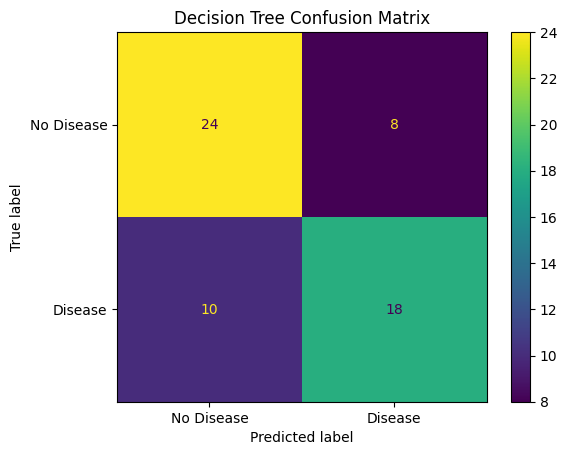

In [69]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Disease", "Disease"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

To evaluate the performance of my Decision Tree model, I trained it using the training set and then evaluated on the test set. The metrics I chose were accuracy, precision, recall, and F1-score. 

It got an accuracy of 0.7, which means that 70% of the test examples were classified correctly. The precision score was 0.692, meaning that when the model predicted heart disease, it was correct around 69.2% of the time. The recall score was 0.643, meaning that the model correctly identified about 64.3% of the actual heart disease cases. Finally, the F1-score was 0.667, which gave a combined measure of precision and recall.

The confusion matrix provided a bit more detail by showing how many patients were correctly and incorrectly classified as having or not having heart disease. This was useful to help with evaluation because the metrics above don't specifically illustrate these issues. The model correctly predicted no-disease or disease more often than it incorrectly gave false positives or negatives.

Overall, the performance of this decision tree classifier was not bad, however it was also by no means a good or very reliable standard.

### 4. Fit two further ensemble models using scikit-learn:

#### - A Random Forest classifier with 500 estimators.
#### - An AdaBoost classifier with 500 estimators.

In [121]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

ada_model = AdaBoostClassifier(
    n_estimators=500,
    random_state=42
)

rf_model.fit(X_train, y_train)
ada_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_ada = ada_model.predict(X_test)

ensemble_results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada)
    ],
    "Precision": [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada)
    ],
    "Recall": [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada)
    ]
})

ensemble_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.867,0.885,0.821,0.852
1,AdaBoost,0.850,0.828,0.857,0.842


### 5. Combine your models from the previous steps in a soft-voting Voting Classifier.

In [124]:
voting_model = VotingClassifier(
    estimators=[
        ("decision_tree", dt_model),
        ("random_forest", rf_model),
        ("adaboost", ada_model)
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)

y_pred_voting = voting_model.predict(X_test)

voting_results = pd.DataFrame({
    "Model": ["Voting Classifier"],
    "Accuracy": [accuracy_score(y_test, y_pred_voting)],
    "Precision": [precision_score(y_test, y_pred_voting)],
    "Recall": [recall_score(y_test, y_pred_voting)],
    "F1-score": [f1_score(y_test, y_pred_voting)]
})

voting_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Voting Classifier,0.717,0.72,0.643,0.679


### 6. Compare the performance of all four models (the decision tree baseline, the Random Forest, the AdaBoost classifier, and the voting classifier) on the test set:

### (a) Create a table of precision, recall, and F1-scores for each model.

In [123]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Voting Classifier"
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada),
        precision_score(y_test, y_pred_voting)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada),
        recall_score(y_test, y_pred_voting)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada),
        f1_score(y_test, y_pred_voting)
    ]
})

model_results.round(3)

,Model,Precision,Recall,F1-score
0,Decision Tree,0.692,0.643,0.667
1,Random Forest,0.885,0.821,0.852
2,AdaBoost,0.828,0.857,0.842
3,Voting Classifier,0.720,0.643,0.679


### (b) Display a confusion matrix for each model.

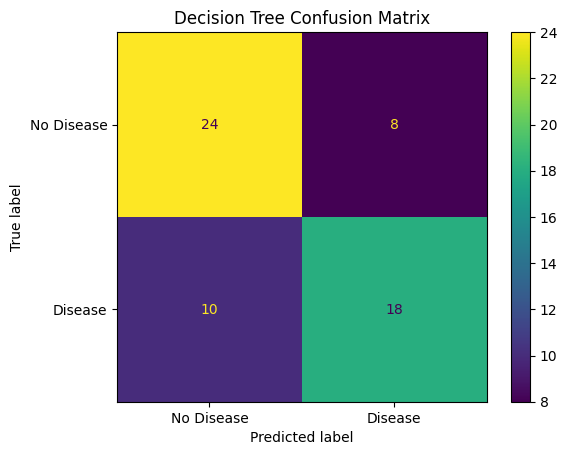

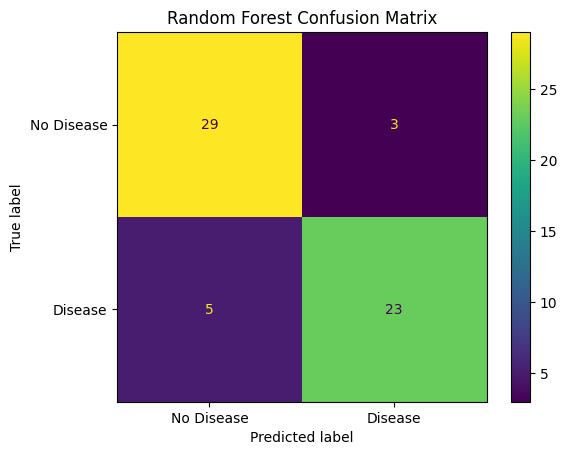

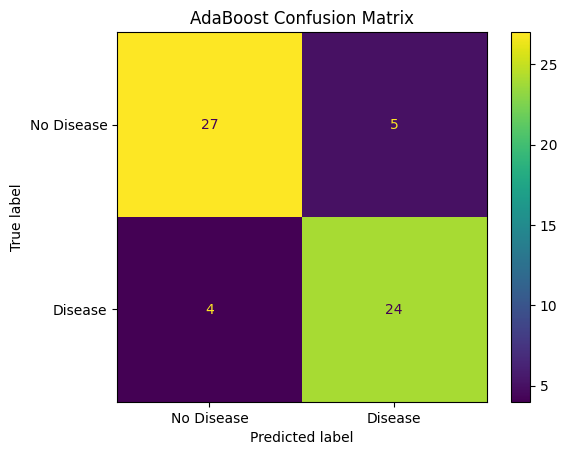

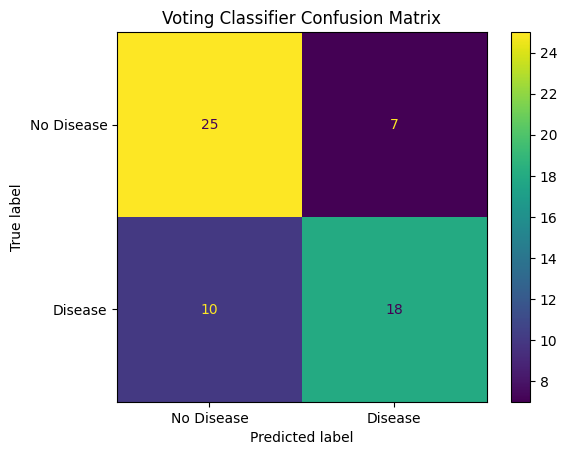

In [125]:
models_and_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "Voting Classifier": y_pred_voting
}

for model_name, predictions in models_and_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Disease"]
    )

    disp.plot()
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

The Random Forest and AdaBoost models performed better than the single Decision Tree baseline. The Decision Tree had the lowest F1-score of 0.667, suggesting that it was less effective at balancing precision and recall.

The Random Forest achieved the highest precision of 0.885 and the highest F1-score of 0.852. This means that when it predicted heart disease, it was usually correct, and it also maintained a strong balance between precision and recall. AdaBoost achieved the highest recall of 0.857, meaning it identified the largest proportion of actual heart disease cases.

The Voting Classifier did not improve on the individual ensemble models. Its F1-score of 0.679 was only slightly better than the Decision Tree baseline and much lower than Random Forest and AdaBoost. This suggests that combining the models by soft voting did not necessarily produce a better classifier in this case.

### 7. Plot the feature importances of your Random Forest. Briefly comment on which features contribute most strongly to predictions, and whether this matches what you would expect.

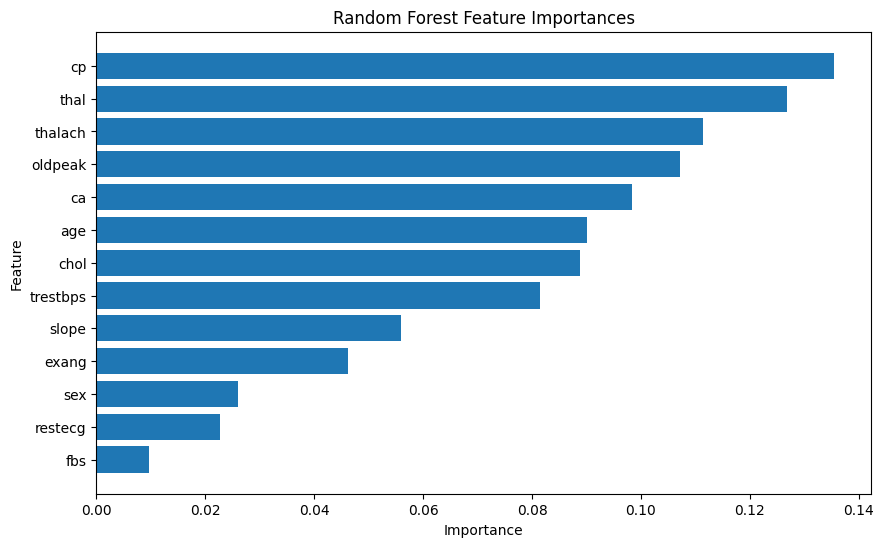

In [126]:
feature_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importances = feature_importances.sort_values(
    by="Importance",
    ascending=False
)

feature_importances

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importances["Feature"],
    feature_importances["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importances")
plt.show()

The feature importance graph above shows that `cp`, `thal`, `thalach`, `oldpeak` and `ca` were the top 5 most important features in order.

I think this aligns with what I would expect. `cp` is chest pain, which obviously is a strong indicator of heart disease, with it being an obvious warning sign for heart attacks too. `thal` is the second most important feature and it refers to the results of a thallium stress test, which measures the blow from through the heart. Clearly adequate blood flow has significance to classifying heart disease. `thalach` is the maximum heart rate achieved would strongly correlate to cardiovascular health issues as ensuring your target heart rate isn't too close to the maximum will ensure that you don't trigger any severe health issues. `oldpeak` refers to the ST depression induced by exercise, which may also point to how the heart copes under stress and exercise. `ca`, the number of major vessels (0-3) coloured by fluoroscopy, is also important because it indicates whether any vessels are blocked and how well the blood flows through your arteries.

Features like as `fbs`, `restecg` and `sex` had the least feature importance for this model. While this doesn't mean they have no correlation in predicting heart disease, it makes sense that for example, sex has less relevance since both men and woman can get heart disease. Nevertheless, women actually often face unique issues and futher cardiovascular issues due to hormones and having smaller hearts. Thus, while the feature importance shows other features contribute more in improving predictions, all the features still provide some insight.

Thus, the feature importance illustrated in the chart does make sense and align with common expectations regarding heart disease.

### 8. Comment on your results in detail. Investigate the following ideas:

#### (a) How do the models compare to each other? Which model performs best? Is this what you expected?

The other models in my ensemble performed better than the Decision Tree baseline. The Decision Tree had the wosrt performance, with precision of 0.692, recall of 0.643 and an F1-score of 0.667. These results emphasise that its predections on the test set weren't very strong.

The Random Forest model got the best precision and F1-score, achieving 0.885 and 0.821 respectively. Its recall was also quite strong at 0.821. This high F1-score means that the model has a strong balance between precision and recall. Practically, it also means that the model caught a lot of actual positive cases, while raising not too many false alarms. It's high precision also means it was more correct than the other models when predicting heart disease.

The AdaBoost algorithm also performed very well with precision, recall, and f1-scores of 0.828, 0.857, and 0.842 respectively. While its precision wasn't as good as the Random Forest's, Adaboost had the highest recall in the ensemble. A high recall compared to precision looks like the model catching nearly all the actual positive cases, but also incorrectly flagging some false positives.

The Soft Voting Classifier did not improve any of the performance metrics, which surprised me a lot. It achieved precision of 0.720, recall of 0.643 and an F1-score of 0.679. These results were only a little bit better than the Decision Tree and a lot worse than the results achieved by my Random Forest and AdaBoost models.

Out of curiousity, I tested using a Hard Voting Classifier instead, which I've shown in the code cell below. The hard voting model performed significantly better than the soft voting model and decision tree model. However, it still could not outperform the stronger AdaBoost and Random Forest models. 

This test gave me some insight into why the original voting classifier performed so poorly and why the second one still wasn't the best. Because soft voting depending on probability estimates, averaging probability estimates probably led to a weaker estimate since the decision tree was a weak model. Even though hard voting reduced this issue, since each model's weight is equal, the weaker decision tree model still impacted the strong results of the other two models.

In [128]:
from sklearn.metrics import precision_score, recall_score, f1_score

hard_voting_model = VotingClassifier(
    estimators=[
        ("decision_tree", dt_model),
        ("random_forest", rf_model),
        ("adaboost", ada_model)
    ],
    voting="hard"
)

hard_voting_model.fit(X_train, y_train)

y_pred_hard_voting = hard_voting_model.predict(X_test)

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Voting Classifier",
        "Hard Voting Classifier"
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada),
        precision_score(y_test, y_pred_voting),
        precision_score(y_test, y_pred_hard_voting)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada),
        recall_score(y_test, y_pred_voting),
        recall_score(y_test, y_pred_hard_voting)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada),
        f1_score(y_test, y_pred_voting),
        f1_score(y_test, y_pred_hard_voting)
    ]
})

model_results.round(3)

,Model,Precision,Recall,F1-score
0,Decision Tree,0.692,0.643,0.667
1,Random Forest,0.885,0.821,0.852
2,AdaBoost,0.828,0.857,0.842
3,Voting Classifier,0.720,0.643,0.679
4,Hard Voting Classifier,0.846,0.786,0.815


### (b) Bagging and boosting reduce different sources of error. Which type of ensemble works better here, and why might that be?


Random Forest is a bagging method. It builds many decision trees using different bootstrap samples of the training data and combines their predictions. This mainly helps reduce variance, because the final prediction is less dependent on one individual tree.

AdaBoost is a boosting method. It builds models sequentially, with later models focusing more on examples that previous models classified incorrectly. This can help reduce bias and improve performance on difficult examples.

In my results, both bagging and boosting worked much better than the single Decision Tree. Random Forest had the highest F1-score, while AdaBoost had the highest recall. This suggests that bagging worked slightly better overall for this dataset because Random Forest had the best balance between precision and recall. However, boosting was also very competitive and may be preferred if the main aim is to reduce false negatives and detect as many actual heart disease cases as possible.

Since the dataset is fairly small, the Random Forest may have benefited from averaging many trees and reducing the instability that a single decision tree can have. This may explain why it performed slightly better overall than AdaBoost.

AdaBoost also performed strongly, with precision of 0.828, recall of 0.857 and an F1-score of 0.842. Although its F1-score was slightly lower than the Random Forest, it had the highest recall. This means AdaBoost identified the largest proportion of actual heart disease cases. In a medical prediction problem, this is important because a false negative would mean a patient with heart disease was predicted as not having heart disease.

### (c) What are the advantages and disadvantages of using an ensemble method over the decision tree baseline?

The main advantage of the ensemble methods is that they performed better than the single Decision Tree. Both Random Forest and AdaBoost achieved much higher precision, recall and F1-scores than the baseline. This shows that combining multiple learners can create a stronger and more reliable model than relying on one decision tree.

Another advantage is that ensemble models are usually less sensitive to the specific training data. A single Decision Tree can overfit by creating splits that work well for the training set but do not generalise well to unseen data. Random Forest reduces this problem by averaging many trees, while AdaBoost improves performance by focusing on examples that are harder to classify.

However, ensemble methods also have disadvantages. They are less interpretable than a single Decision Tree because their predictions come from many trees or learners rather than one simple model. They can also take longer to train and may be harder to explain clearly. This matters in a medical-style prediction problem, where interpretability can be important.

Overall, the ensemble models gave better predictive performance, but this came at the cost of reduced simplicity and interpretability. The Decision Tree baseline was easier to understand, but the Random Forest and AdaBoost models were more accurate and reliable on the test set.

## Part 2 - Clustering of Faces

### 1. Load the Olivetti Faces dataset using the code above.

In [110]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

data, targets = fetch_olivetti_faces(return_X_y=True)

print("Data shape:", data.shape)
print("Targets shape:", targets.shape)
print("Number of classes:", len(np.unique(targets)))

Data shape: (400, 4096)
Targets shape: (400,)
Number of classes: 40


### Briefly describe the dataset:

### (a) How many examples are there? What does each example represent?

The Olivetti Faces dataset has 400 examples, as shown in the code cell output above. Each example represents a greyscale image of a person's face taken between 1992 and 1994 in Cambridge. There are 10 images each for 40 different people, which reflect the 40 classes.

### (b) Describe the features. How many features are there, and what does each feature represent?

There are 4096 features, which you can see as each image of a face is 64 x 64 pixels = 4096. Each feature represents the intensity of a pixel in the image of one of the Olivetti Faces. The dataset stores each image as a flattened 1-dimensional vector with 4096 features.

### 2. Sample a random example from each class and display the images in a grid. Ensure each image is labelled with its class.

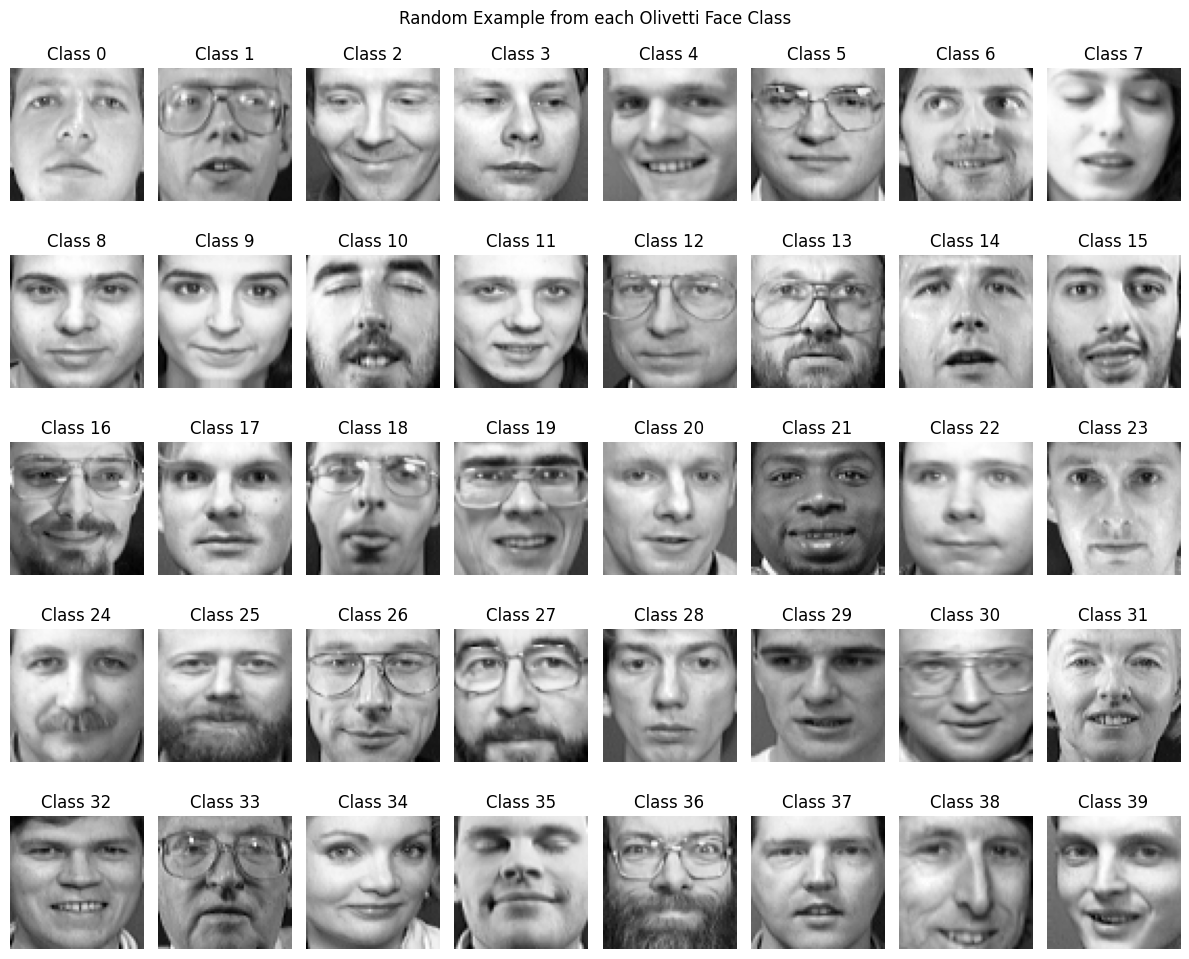

In [129]:
np.random.seed(42)

classes = np.unique(targets)
selected_indices = []

for class_label in classes:
    class_indices = np.where(targets == class_label)[0]
    random_index = np.random.choice(class_indices)
    selected_indices.append(random_index)

plt.figure(figsize=(12, 10))

for i, index in enumerate(selected_indices):
    plt.subplot(5, 8, i + 1)
    plt.imshow(data[index].reshape(64, 64), cmap="gray")
    plt.title(f"Class {targets[index]}")
    plt.axis("off")

plt.suptitle("Random Example from each Olivetti Face Class")
plt.tight_layout()
plt.show()

### 3. Fit Principal Component Analysis (PCA) on the full dataset using scikit-learn.

### (a) Plot the cumulative explained variance ratio against the number of components. Choose a number of components that retains at least 95% of the variance and report this number.

In [112]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(data)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components needed to retain at least 95% variance:", n_components_95)

Number of components needed to retain at least 95% variance: 123


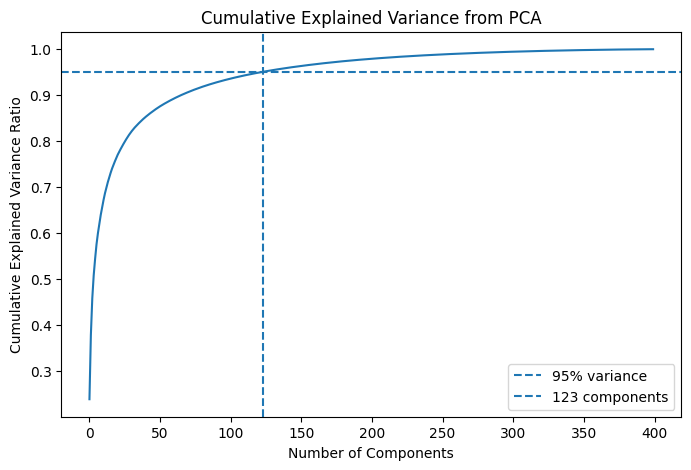

In [113]:
plt.figure(figsize=(8, 5))
plt.plot(cumulative_variance)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.axvline(x=n_components_95, linestyle="--", label=f"{n_components_95} components")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("Cumulative Explained Variance from PCA")
plt.legend()
plt.show()

### (b) Display the first 10 principal components as 64 × 64 images. These are known as eigenfaces. Explain what these components represent and how they relate to the original images.

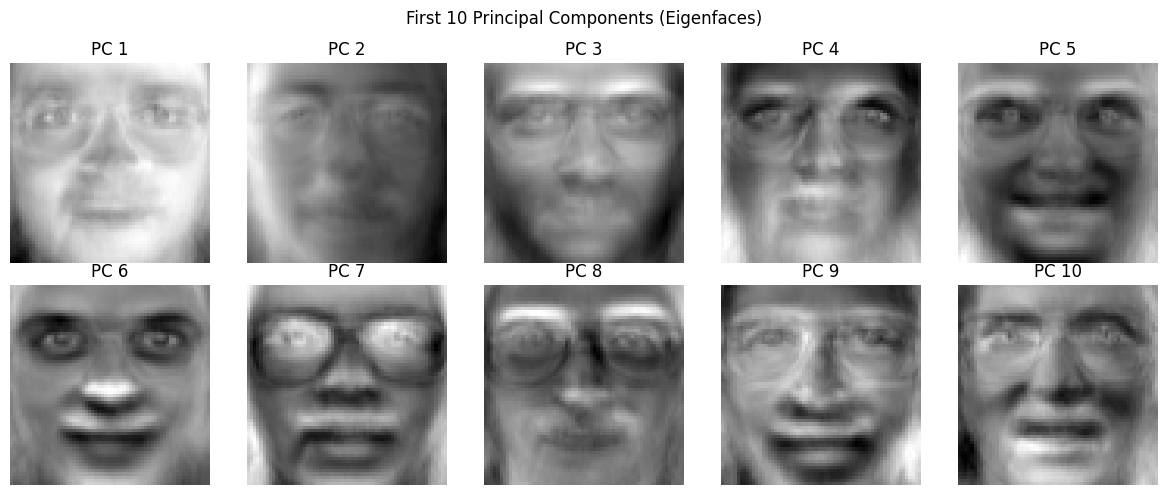

In [130]:
plt.figure(figsize=(12, 5))

for i in range(10):
    eigenface = pca.components_[i].reshape(64, 64)

    plt.subplot(2, 5, i + 1)
    plt.imshow(eigenface, cmap="gray")
    plt.title(f"PC {i + 1}")
    plt.axis("off")

plt.suptitle("First 10 Principal Components (Eigenfaces)")
plt.tight_layout()
plt.show()

Eigenfaces are defined as a set of greyscale images that seem "ghost-like" and act as the basis for facial recognition in computer vision. They aren't actually real faces from the dataset, but they show specific variations that can be found across the face images. By applying different multipliers to the eigenfaces, you could reconstruct a specific person's face from the dataset.

The first few eigenfaces show the biggest patterns that change across the dataset. For example, some components seem to show the differences in brightness and shadows, while others show changes in facial position, outline, or movement around areas like the eyes or mouth. These patterns relate to the original images because each face can be represented or reconstructed as a weighted combination of the eigenfaces, as mentioned earlier. Instead of storing all the 4096 pixels, PCA describes each image using a smaller number of these important patterns through the first 10 PCs.

### (c) Project the data onto the first two principal components and produce a scatter plot, colouring each point by its class. Comment on whether 2 components are sufficient to separate the classes.

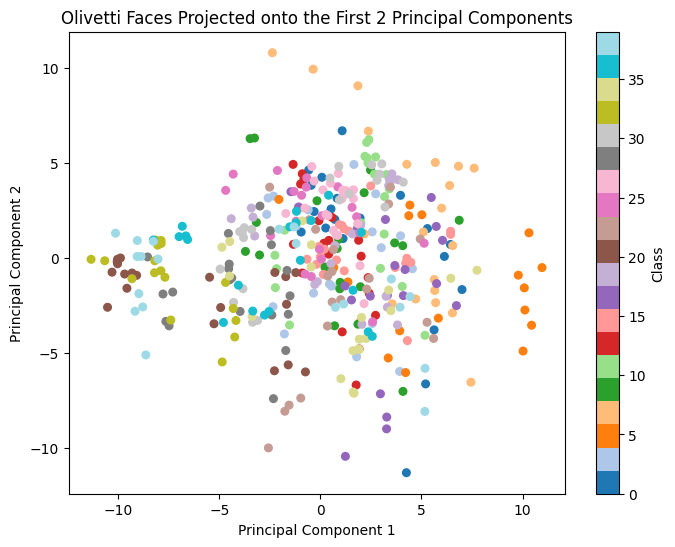

In [133]:
pca_2 = PCA(n_components=2)
data_2d = pca_2.fit_transform(data)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    data_2d[:, 0],
    data_2d[:, 1],
    c=targets,
    cmap="tab20",
    s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Olivetti Faces Projected onto the First 2 Principal Components")
plt.colorbar(scatter, label="Class")
plt.show()

The scatter plot above shows the Olivetti Faces dataset being projected onto the first two principal components. As the task specifies, each point is coloured to represent one image and the colour represents its class, or whose face it is.

I don't think two principal components is enough to separate the classes. As you can see, the different classes are hard to distinguish and they don't necessarily form visible clusters. For the sake of investigation, I checked out how the dataset would look if it was projected onto 3 principal components, and even this still didn't make it clear to distinguish the classes. This is expected because reducing the dimensionality of the original 4096 features into two or three components loses a lot of information.

### 4. Apply k-Means clustering to the original feature space. Use k equal to the number of classes.

### (a) Report the silhouette score of the clustering.

In [136]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_original = KMeans(
    n_clusters=40,
    random_state=42,
    n_init=10
)

cluster_labels_original = kmeans_original.fit_predict(data)

silhouette_original = silhouette_score(data, cluster_labels_original)

print("Silhouette score for k-Means on original feature space:", silhouette_original)

Silhouette score for k-Means on original feature space: 0.14647039771080017


The silhouette score for k-Means on the original feature space is around 0.1465 as shown above. This implies that the clusters are weakly separated with overlapping clusters. This low silhouette score is expected though because images of faces are high-dimensional and the real classes may not form simple clusters in the raw pixel space.

### (b) Visualise the cluster centroids as 64 × 64 images. Compare them to the eigenfaces from the previous task.

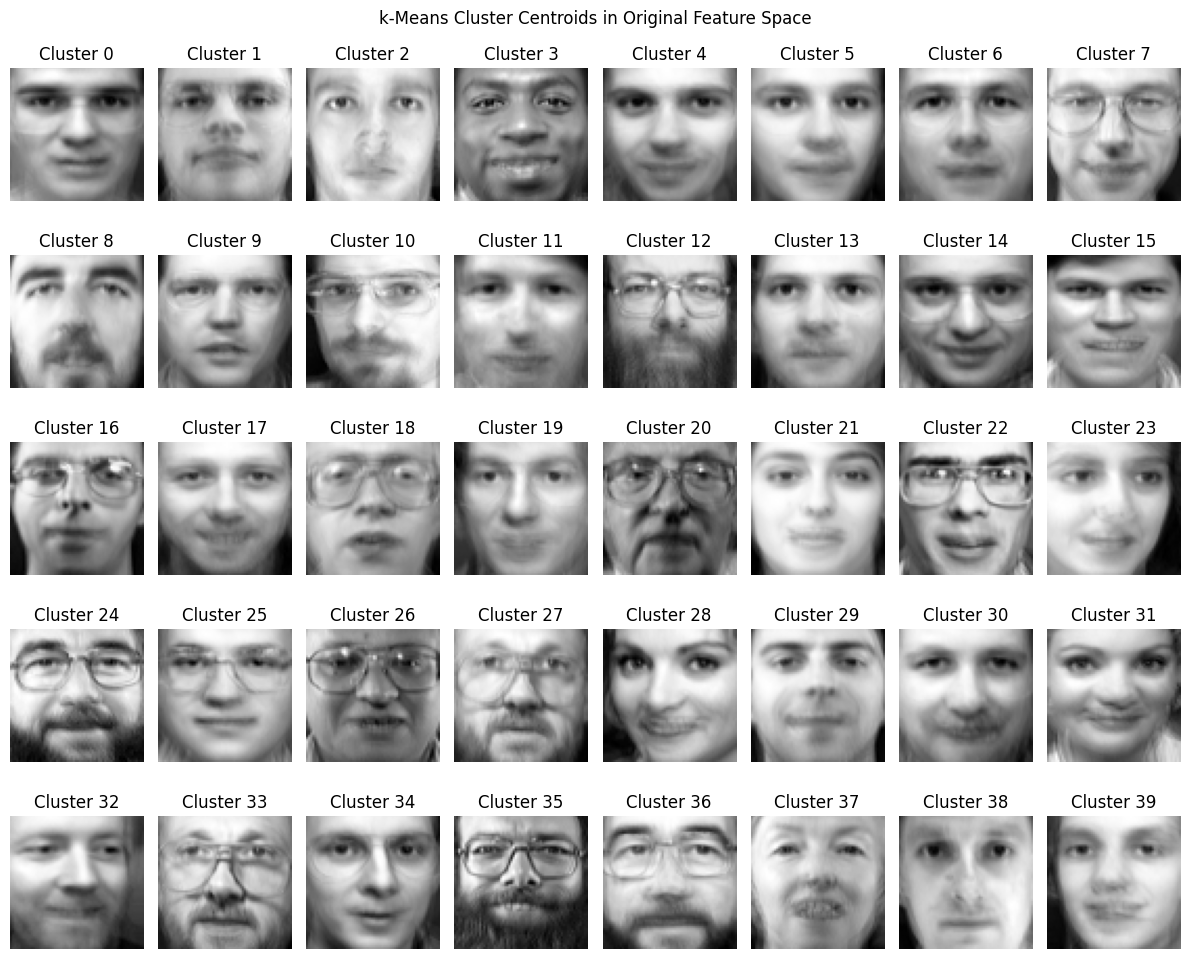

In [137]:
centroids_original = kmeans_original.cluster_centers_

plt.figure(figsize=(12, 10))

for i in range(40):
    plt.subplot(5, 8, i + 1)
    plt.imshow(centroids_original[i].reshape(64, 64), cmap="gray")
    plt.title(f"Cluster {i}")
    plt.axis("off")

plt.suptitle("k-Means Cluster Centroids in Original Feature Space")
plt.tight_layout()
plt.show()

After applying k-means clustering, the centroids for each cluster were reshaped as 64x64 images. They ended up looking similar to the original individual faces, but appearing a bit more blurry and almost uncanny. This is because each centroid was calculated by finding the average of all pixel values for all the images assigned to that cluster.

Comparing these cluster centroids to the eigenfaces from the previous task, these images look more like faces, are a bit clearer, and less "ghost-like". This is because the centroids show the centre of each cluster of images in the original pixel space, whereas the eigenfaces show variations in the dataset. The eigenfaces do not correspond to a specific cluster or class, but rather showed patterns like lighting, facial structures, etc., making them less human-like to a viewer. 

### 5. Repeat the k-Means clustering, this time on the PCA-reduced data.

### (a) Report the silhouette score for the PCA-reduced clustering.

In [142]:
pca_reduced = PCA(n_components=n_components_95)

data_pca_reduced = pca_reduced.fit_transform(data)

kmeans_pca = KMeans(
    n_clusters=40,
    random_state=42,
    n_init=10
)

cluster_labels_pca = kmeans_pca.fit_predict(data_pca_reduced)

silhouette_pca = silhouette_score(data_pca_reduced, cluster_labels_pca)

print("Silhouette score for k-Means on original feature space:", silhouette_original)
print("Silhouette score for k-Means on the PCA reduced data:", silhouette_pca)

Silhouette score for k-Means on original feature space: 0.14647039771080017
Silhouette score for k-Means on the PCA reduced data: 0.17367535829544067


As shown above, the silhouette score increased from around 0.146 to 0.175 on PCA reduced data. This shows that PCA imporved the clustering a little bit, but since both scores are quite low, this means the clusters aren't very strongly separated.

### (b) Plot the silhouette diagrams for both the original and PCA-reduced clusterings, and compare them.

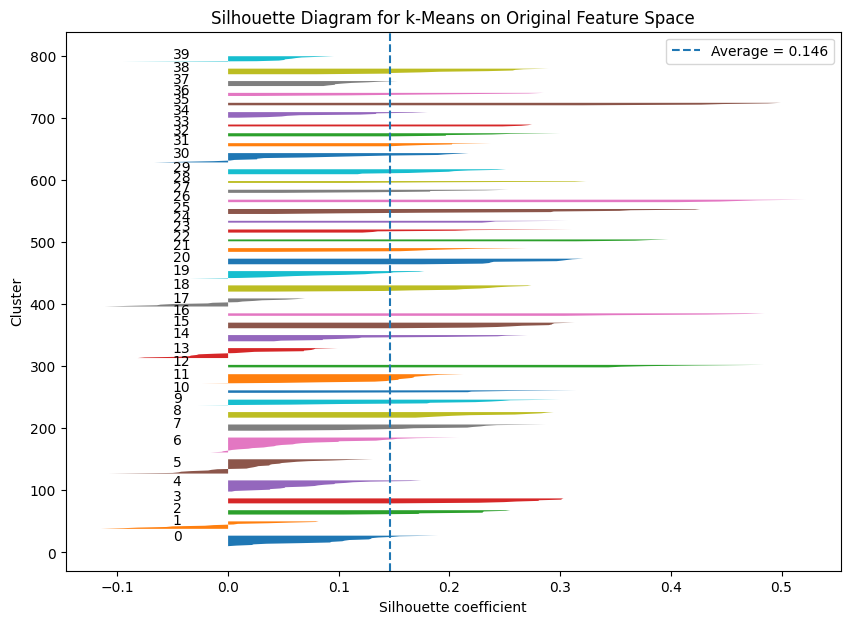

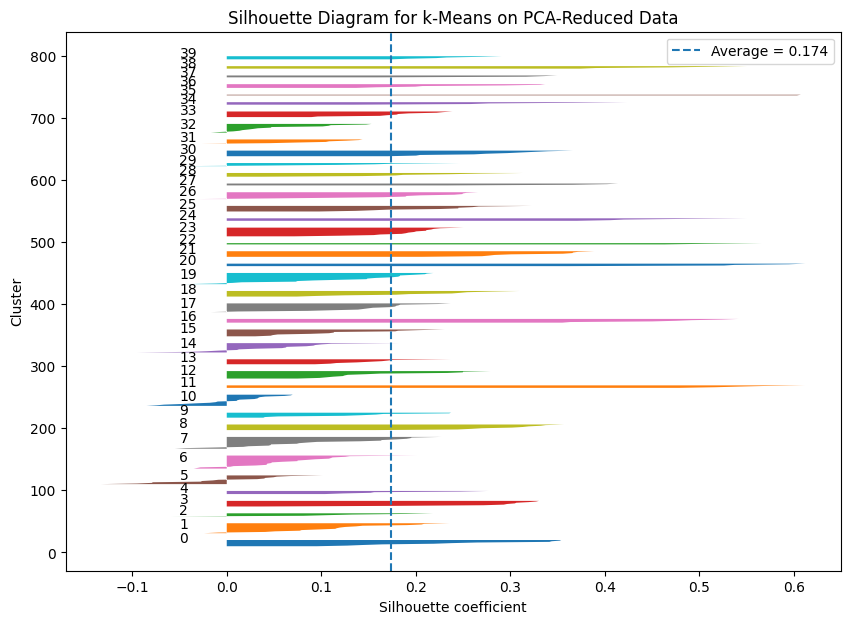

In [143]:
from sklearn.metrics import silhouette_samples

def plot_silhouette_diagram(X, cluster_labels, title):
    silhouette_values = silhouette_samples(X, cluster_labels)
    average_score = silhouette_score(X, cluster_labels)

    plt.figure(figsize=(10, 7))

    y_lower = 10

    for cluster in range(40):
        cluster_silhouette_values = silhouette_values[cluster_labels == cluster]
        cluster_silhouette_values.sort()

        cluster_size = cluster_silhouette_values.shape[0]
        y_upper = y_lower + cluster_size

        plt.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_silhouette_values
        )

        plt.text(-0.05, y_lower + 0.5 * cluster_size, str(cluster))

        y_lower = y_upper + 10

    plt.axvline(x=average_score, linestyle="--", label=f"Average = {average_score:.3f}")

    plt.xlabel("Silhouette coefficient")
    plt.ylabel("Cluster")
    plt.title(title)
    plt.legend()
    plt.show()

plot_silhouette_diagram(
    data,
    cluster_labels_original,
    "Silhouette Diagram for k-Means on Original Feature Space"
)

plot_silhouette_diagram(
    data_pca_reduced,
    cluster_labels_pca,
    "Silhouette Diagram for k-Means on PCA-Reduced Data"
)

The silhouette score for k-Means on the original feature space was [insert original score]. The silhouette score for k-Means on the PCA-reduced data was [insert PCA score].

The silhouette diagrams show how well each image fits within its assigned cluster. Wider positive regions indicate better-separated clusters, while values close to 0 indicate overlapping clusters. Negative values suggest that some images may have been assigned to the wrong cluster.

In this experiment, the silhouette scores were relatively low, which suggests that the face images do not form very clearly separated clusters. This is expected because the Olivetti Faces dataset contains images that may vary by lighting, pose and facial expression. Also, k-Means assumes roughly spherical clusters, which may not match the true structure of face image data.

Comparing the two diagrams, the PCA-reduced clustering [improved/did not improve] the silhouette score compared with the original feature space. PCA can help clustering by removing noise and reducing dimensionality, but it can also remove some information that may be useful for separating individual people. Therefore, the effect of PCA depends on whether the retained components capture the most useful differences between faces.


This indicates that PCA slightly improved the clustering quality. However, both scores are low, so the clusters are still not strongly separated. This is expected because face images are complex and may overlap due to lighting, pose and expression differences. PCA likely helped by reducing noise and compressing the original 4096 pixel features into a smaller set of more informative components, but k-Means still struggled to clearly separate all 40 classes.